# Transformacja Gabora i sygnatury energii w rozpoznawaniu obrazów

**Autor:** Jakub Psarski <br />
**Data:** 10.11.2026

Program wyszukuje w bazie emotikonę najbardziej podobną do zapytania. Obraz jest filtrowany bankiem filtrów Gabora (różne długości fali i orientacje), a dla każdej odpowiedzi filtru liczona jest jej energia (średnia wartość bezwzględna i odchylenie standardowe). Tak powstały wektor to sygnatura energii obrazu. Wyszukiwanie odbywa się algorytmem k-NN.

## Importy i parametry

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from sklearn.neighbors import KNeighborsClassifier

np.random.seed(0)
N_QUERIES = 200
WAVELENGTHS = [4, 8, 16]
N_ORIENTATIONS = 6
KSIZE = 21
K = 5

## Baza emotikon i zapytania

In [2]:
def make_emoji(c):
    img = np.zeros((64, 64), np.uint8)
    cv2.circle(img, (32, 32), 24, 255, -1)
    cv2.circle(img, (24, 24), 4, 0, -1)
    cv2.circle(img, (40, 24), 4, 0, -1)
    if c == 0:
        cv2.ellipse(img, (32, 36), (13, 10), 0, 0, 180, 0, -1)
    elif c == 1:
        cv2.ellipse(img, (32, 48), (12, 7), 0, 180, 360, 0, 4)
    elif c == 2:
        cv2.rectangle(img, (21, 40), (43, 44), 0, -1)
    else:
        cv2.circle(img, (32, 42), 7, 0, -1)
    return img


def transform(img):
    M = cv2.getRotationMatrix2D(
        (32, 32),
        np.random.uniform(-30, 30),
        np.random.uniform(0.7, 1.1)
    )
    M[0, 1] += np.random.uniform(-0.2, 0.2)
    M[:, 2] += np.random.uniform(-5, 5, 2)
    return cv2.warpAffine(img, M, (64, 64), flags=cv2.INTER_NEAREST)


names = np.array(["happy", "sad", "neutral", "surprised"])
db_labels = np.repeat(np.arange(4), 100)
db_imgs = np.array([transform(make_emoji(c)) for c in db_labels])
q_labels = np.random.randint(4, size=N_QUERIES)
q_imgs = np.array([transform(make_emoji(c)) for c in q_labels])
print("database size:", len(db_imgs))
print("queries:", len(q_imgs))

database size: 400
queries: 200


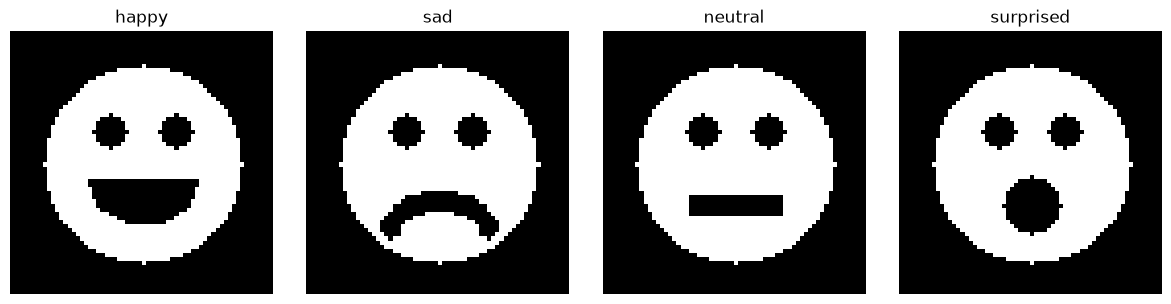

In [3]:
plt.figure(figsize=(12, 3))
for c in range(4):
    plt.subplot(1, 4, c + 1)
    plt.imshow(make_emoji(c), cmap="gray")
    plt.title(names[c])
    plt.axis("off")
plt.tight_layout()
plt.show()

## Bank filtrów Gabora

number of filters: 18


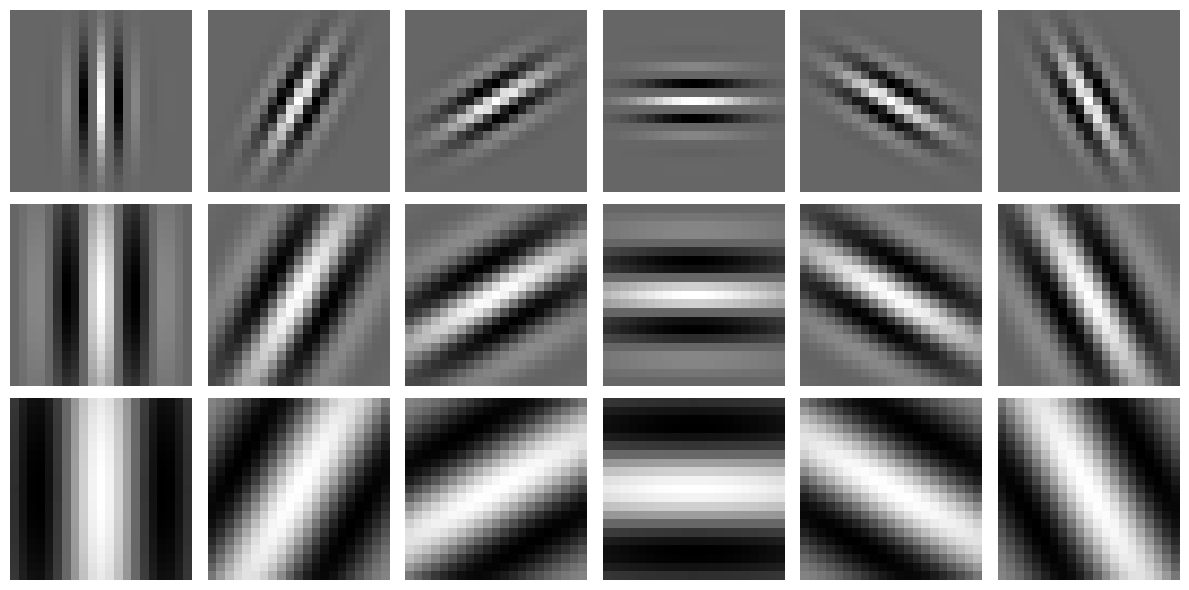

In [4]:
def gabor_bank(wavelengths, n_orientations):
    bank = []
    for lam in wavelengths:
        for theta in np.arange(n_orientations) * np.pi / n_orientations:
            bank.append(
                cv2.getGaborKernel((KSIZE, KSIZE), 0.56 * lam, theta, lam, 0.5, 0)
            )
    return bank


bank = gabor_bank(WAVELENGTHS, N_ORIENTATIONS)
print("number of filters:", len(bank))

plt.figure(figsize=(12, 6))
for i, kernel in enumerate(bank):
    plt.subplot(len(WAVELENGTHS), N_ORIENTATIONS, i + 1)
    plt.imshow(kernel, cmap="gray")
    plt.axis("off")
plt.tight_layout()
plt.show()

## Sygnatury energii

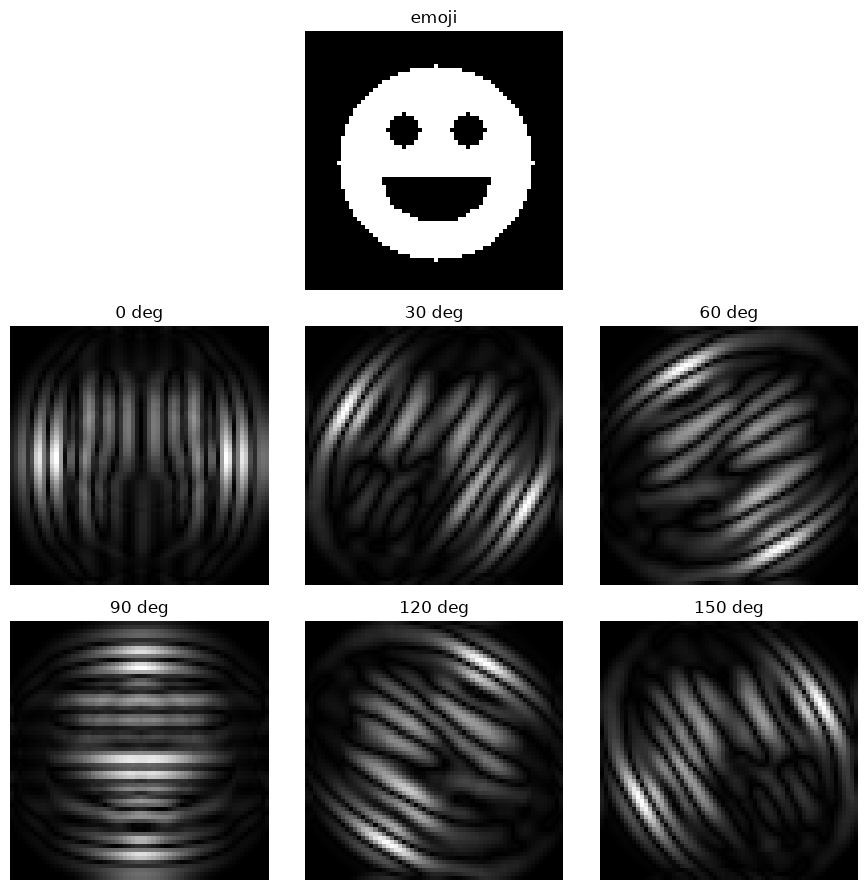

energy features: (36,)


In [5]:
def energy_features(img, bank):
    img = img / 255.0
    features = []
    for kernel in bank:
        response = cv2.filter2D(img, cv2.CV_64F, kernel)
        features += [np.abs(response).mean(), response.std()]
    return np.array(features)


img = make_emoji(0)
plt.figure(figsize=(9, 9))
plt.subplot(3, 3, 2)
plt.imshow(img, cmap="gray")
plt.title("emoji")
plt.axis("off")
for i in range(N_ORIENTATIONS):
    response = cv2.filter2D(img / 255.0, cv2.CV_64F, bank[N_ORIENTATIONS + i])
    plt.subplot(3, 3, i + 4)
    plt.imshow(np.abs(response), cmap="gray")
    plt.title(f"{180 * i // N_ORIENTATIONS} deg")
    plt.axis("off")
plt.tight_layout()
plt.show()

print("energy features:", energy_features(img, bank).shape)

## Wyszukiwanie k-NN

In [6]:
def features(bank):
    D = np.array([energy_features(im, bank) for im in db_imgs])
    Q = np.array([energy_features(im, bank) for im in q_imgs])
    mean, std = D.mean(axis=0), D.std(axis=0) + 1e-9
    return (D - mean) / std, (Q - mean) / std


def knn_accuracy(D, Q, k):
    knn = KNeighborsClassifier(n_neighbors=k).fit(D, db_labels)
    return np.mean(knn.predict(Q) == q_labels) * 100


D, Q = features(bank)
print(f"Gabor energy signatures, k={K}: {knn_accuracy(D, Q, K):.1f}%")

Gabor energy signatures, k=5: 91.0%


## Wpływ liczby sąsiadów k

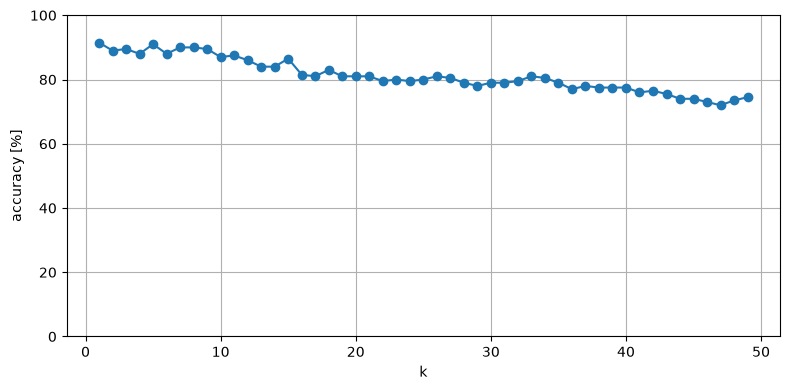

In [7]:
ks = range(1, 50)
acc_k = [knn_accuracy(D, Q, k) for k in ks]

plt.figure(figsize=(8, 4))
plt.plot(ks, acc_k, marker="o")
plt.xlabel("k")
plt.ylabel("accuracy [%]")
plt.ylim(0, 100)
plt.grid()
plt.tight_layout()
plt.show()

## Wpływ parametrów banku filtrów

1 scale, 4 orientations    accuracy: 74.0%
1 scale, 8 orientations    accuracy: 84.5%
2 scales, 4 orientations   accuracy: 74.5%
2 scales, 8 orientations   accuracy: 92.5%
3 scales, 4 orientations   accuracy: 82.5%
3 scales, 6 orientations   accuracy: 91.0%
3 scales, 8 orientations   accuracy: 93.0%


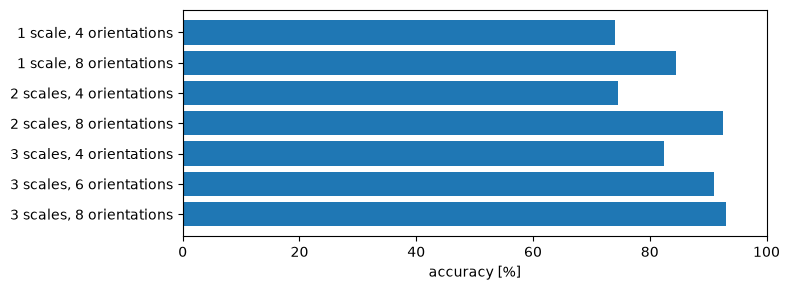

In [8]:
configs = {
    "1 scale, 4 orientations": ([8], 4),
    "1 scale, 8 orientations": ([8], 8),
    "2 scales, 4 orientations": ([4, 8], 4),
    "2 scales, 8 orientations": ([4, 8], 8),
    "3 scales, 4 orientations": ([4, 8, 16], 4),
    "3 scales, 6 orientations": ([4, 8, 16], 6),
    "3 scales, 8 orientations": ([4, 8, 16], 8),
}

results = {
    name: knn_accuracy(*features(gabor_bank(*cfg)), K) 
    for name, cfg in configs.items()
}

for name, acc in results.items():
    print(f"{name:26s} accuracy: {acc:.1f}%")

plt.figure(figsize=(8, 3))
plt.barh(list(results.keys()), list(results.values()))
plt.xlabel("accuracy [%]")
plt.xlim(0, 100)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Przykładowe wyniki wyszukiwania

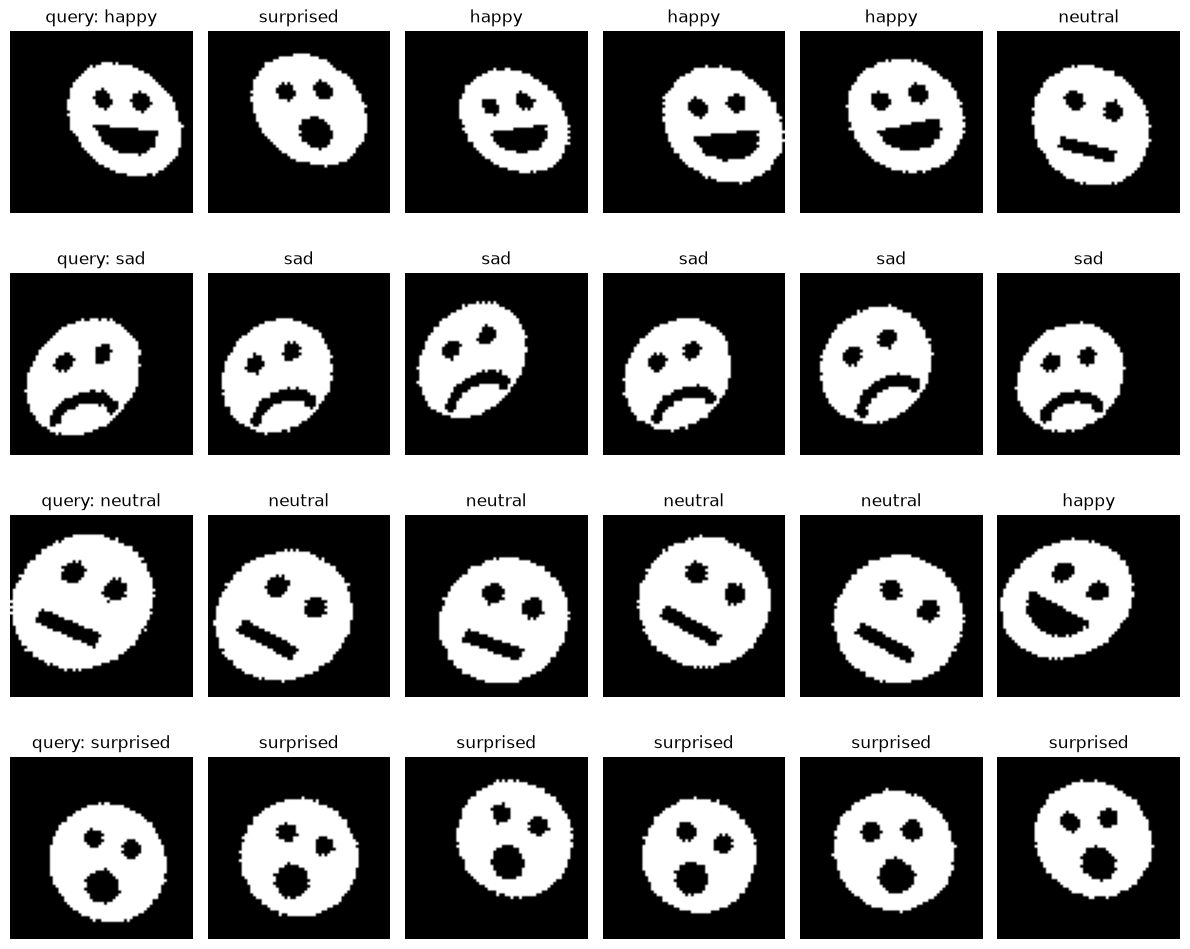

In [9]:
knn = KNeighborsClassifier(n_neighbors=K).fit(D, db_labels)
examples = [np.where(q_labels == c)[0][0] for c in range(4)]

plt.figure(figsize=(12, 10))
for r, q in enumerate(examples):
    _, idx = knn.kneighbors(Q[q:q + 1], n_neighbors=K)
    plt.subplot(4, K + 1, (K + 1) * r + 1)
    plt.imshow(q_imgs[q], cmap="gray")
    plt.title("query: " + names[q_labels[q]])
    plt.axis("off")
    for j, found in enumerate(idx[0]):
        plt.subplot(4, K + 1, (K + 1) * r + j + 2)
        plt.imshow(db_imgs[found], cmap="gray")
        plt.title(names[db_labels[found]])
        plt.axis("off")
plt.tight_layout()
plt.show()

## Wnioski

Sygnatury energii z banku filtrów Gabora dobrze nadają się do rozpoznawania emotikon – dla 3 skal, 6 orientacji i k=5 skuteczność wynosi 91%. Filtr Gabora reaguje na krawędzie o określonej orientacji i grubości, więc energia jego odpowiedzi mówi, ile w obrazie jest struktur danego kierunku i rozmiaru, a to różni kształty ust. Energia nie zależy od położenia na obrazie, więc cechy są odporne na przesunięcie. Najwięcej daje zwiększanie liczby orientacji: przy 4 orientacjach skuteczność wynosi 74–82,5%, a przy 8 już 84,5–93%. Dodanie kolejnych skal też pomaga (przy 4 orientacjach z 74% do 82,5%). Liczba sąsiadów k ma mały wpływ – dla k od 1 do 9 wynik mieści się w przedziale ok. 88–91,5%, a dla większych k lekko spada, bo do głosowania wchodzi więcej obrazów z innych klas.